In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

In [2]:
import os

for file in os.listdir():
    print(file)


.adk
.anaconda
.android
.antigravity
.aws
.azure
.bash_history
.cache
.cagent
.claude
.claude.json
.conda
.config
.continuum
.copilot
.cursor
.docker
.emulator_console_auth_token
.gemini
.git-for-windows-updater
.gitconfig
.github-copilot-cli
.gradle
.icesoft
.idlerc
.ipynb_checkpoints
.ipython
.jupyter
.lesshst
.local
.mcp-auth
.ms-ad
.ollama
.openjfx
.packettracer
.python_history
.redhat
.venv
.vscode
.vscode-shared
adk-workspace
adk-worktable
agent.py
anaconda3
AndroidStudioProjects
AppData
Application Data
Cisco Packet Tracer 9.0.1
Contacts
control
Cookies
Desktop
Documents
Downloads
edb_npgsql.exe
edb_pgagent_pg17.exe
edb_pgagent_pg18.exe
edb_pgbouncer.exe
edb_pgbouncer.exe-20260604012215
edb_pgjdbc.exe
edb_psqlodbc.exe
Favorites
flutter
git1
git_tutorial
go
go-cli
google-agent
GoProjects
hello-go.go
hello_world
Links
Little-Italy_projects
live session
Local Settings
Microsoft
Music
My Documents
my_2nd_agent
my_first_agent
NetHood
node_modules
NTUSER.DAT
ntuser.dat.LOG1
ntuser.dat

In [3]:
df = pd.read_csv("superstore_sales (2).csv")

In [4]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2.0,0.00,41.9136
1,2,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3.0,0.00,219.5820
2,3,CA-2017-138688,6/12/2017,6/16/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2.0,0.00,6.8714
3,4,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5.0,0.45,-383.0310
4,5,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2.0,0.20,2.5164


In [5]:
df.columns

Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State',
       'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category',
       'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit'],
      dtype='str')

Exploratory Data Analysis (EDA) on Superstore Retail Sales
Objective
The objective of this analysis is to examine customer purchase volume, monthly seasonality, category-wise revenue, and discount sensitivity using the Superstore Sales dataset.

The analysis includes:

Data cleaning
Missing value assessment
Category analysis
Region analysis
Customer segment analysis
Monthly sales trend analysis
Discount vs Profit analysis
Executive business insights

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10800 entries, 0 to 10799
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         10800 non-null  str    
 1   Order ID       10800 non-null  str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9983 non-null   float64
 12  Region         9994 non-null   str    
 13  Product ID     9994 non-null   str    
 14  Category       9994 non-null   str    
 15  Sub-Category   9994 non-null   str    
 16  Product Name   9994 non-null   str    
 17  Sales          9994 non-null   float64
 18  Quantity       99

In [7]:
df.isnull().sum()

Row ID             0
Order ID           0
Order Date       806
Ship Date        806
Ship Mode        806
Customer ID      806
Customer Name    806
Segment          806
Country          806
City             806
State            806
Postal Code      817
Region           806
Product ID       806
Category         806
Sub-Category     806
Product Name     806
Sales            806
Quantity         806
Discount         806
Profit           806
dtype: int64

In [8]:
# Remove missing values
df = df.dropna()

# Check dataset shape after cleaning
df.shape

(9983, 21)

In [9]:
df['Order Date'] = pd.to_datetime(df['Order Date'])

In [10]:
df['Year_Month'] = df['Order Date'].dt.to_period('M')

In [11]:
df[['Order Date', 'Year_Month']].head()

,Order Date,Year_Month
0,2017-11-08,2017-11
1,2017-11-08,2017-11
2,2017-06-12,2017-06
3,2016-10-11,2016-10
4,2016-10-11,2016-10


In [12]:
category_sales = df.groupby('Category')['Sales'].sum().sort_values(ascending=False)

category_sales

Category
Technology         834554.2730
Furniture          736879.6953
Office Supplies    716837.5220
Name: Sales, dtype: float64

Finding 1
Technology generated the highest revenue ($834,554), outperforming Furniture and Office Supplies. This indicates strong customer demand for technology products and suggests opportunities for further investment in this category.

C:\Users\Anvar\AppData\Local\Temp\ipykernel_23572\4086195076.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


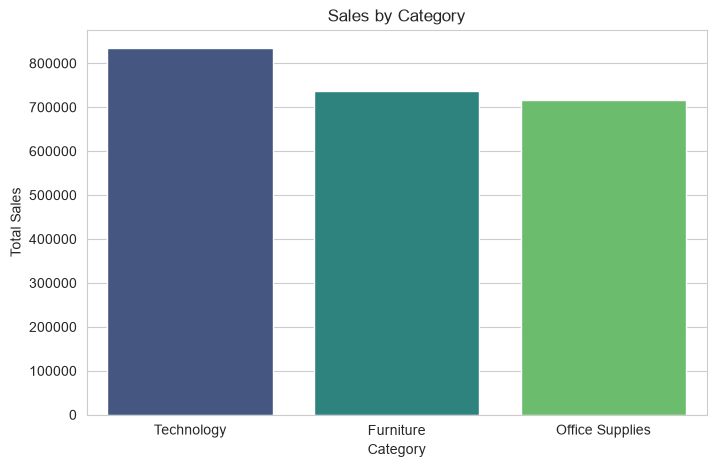

In [13]:
plt.figure(figsize=(8,5))

sns.barplot(
    x=category_sales.index,
    y=category_sales.values,
    palette="viridis"
)

plt.title("Sales by Category")
plt.xlabel("Category")
plt.ylabel("Total Sales")

plt.show()

In [14]:
region_analysis = df.groupby('Region')[['Sales','Profit']].sum()

region_analysis


,Sales,Profit
Region,,
Central,501239.8908,39706.3625
East,669851.8700,89277.8017
South,391721.9050,46749.4303
West,725457.8245,108418.4489


Finding 2
The West region generated both the highest sales ($725,458) and the highest profit ($108,418), making it the strongest-performing region in the business

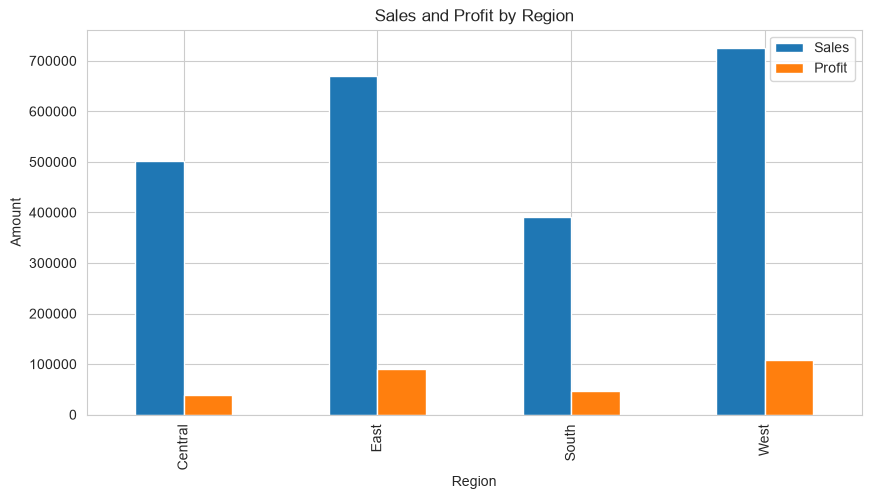

In [15]:
region_analysis.plot(
    kind='bar',
    figsize=(10,5)
)

plt.title("Sales and Profit by Region")
plt.xlabel("Region")
plt.ylabel("Amount")

plt.show()

In [16]:
segment_analysis = df.groupby('Segment')[['Sales','Profit']].sum()

segment_analysis

,Sales,Profit
Segment,,
Consumer,1.160049e+06,133744.0932
Corporate,6.998641e+05,90445.9067
Home Office,4.283584e+05,59962.0435


Finding 3
The Consumer segment generated the highest sales ($1.16 million) and profit ($133,744), making it the most valuable customer segment for the business.

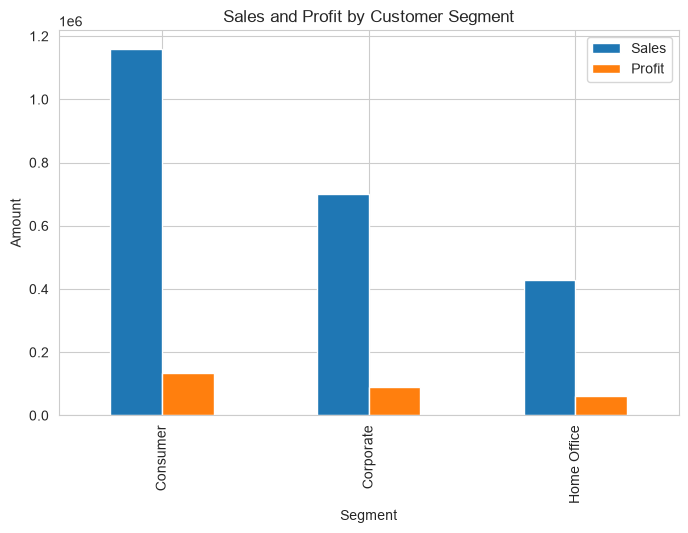

In [17]:
segment_analysis.plot(
    kind='bar',
    figsize=(8,5)
)

plt.title("Sales and Profit by Customer Segment")
plt.xlabel("Segment")
plt.ylabel("Amount")

plt.show()

In [18]:
monthly_sales = df.groupby('Year_Month')['Sales'].sum()

monthly_sales

Year_Month
2015-01     14236.8950
2015-02      4519.8920
2015-03     55691.0090
2015-04     28295.3450
2015-05     23648.2870
2015-06     34595.1276
2015-07     33946.3930
2015-08     27909.4685
2015-09     81777.3508
2015-10     31453.3930
2015-11     78628.7167
2015-12     69545.6205
2016-01     18174.0756
2016-02     11951.4110
2016-03     38726.2520
2016-04     34195.2085
2016-05     30131.6865
2016-06     24797.2920
2016-07     28765.3250
2016-08     36898.3322
2016-09     64595.9180
2016-10     31404.9235
2016-11     70852.4635
2016-12     74919.5212
2017-01     16870.1810
2017-02     22978.8150
2017-03     51715.8750
2017-04     37455.2890
2017-05     56987.7280
2017-06     40344.5340
2017-07     39261.9630
2017-08     31115.3743
2017-09     73410.0249
2017-10     59687.7450
2017-11     79411.9658
2017-12     96999.0430
2018-01     43334.1940
2018-02     20301.1334
2018-03     58872.3528
2018-04     36521.5361
2018-05     44261.1102
2018-06     52981.7257
2018-07     45264.4160


Finding 4
Monthly sales exhibit clear seasonality patterns. Sales typically increased during the final quarter of each year, with November 2018 recording the highest monthly sales ($118,448).

In [19]:
df[['Discount','Profit']].corr()

,Discount,Profit
Discount,1.000000,-0.219182
Profit,-0.219182,1.000000


Finding 5
A negative correlation (-0.219) exists between discount and profit, indicating that aggressive discounting may reduce profitability

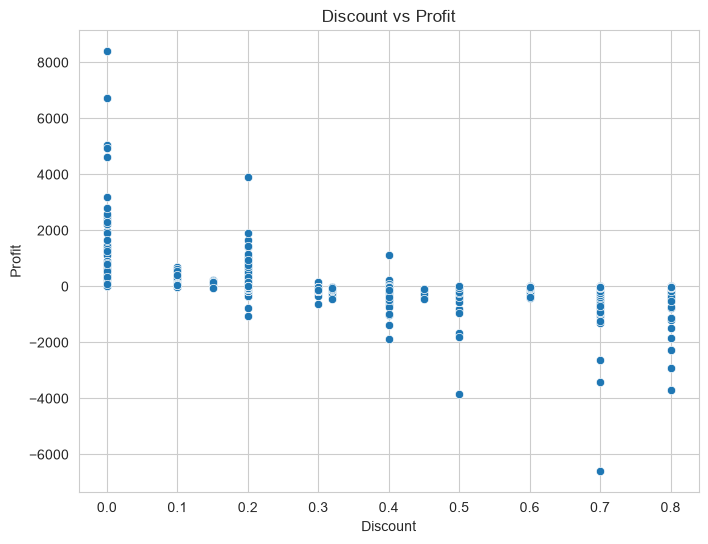

In [20]:
plt.figure(figsize=(8,6))

sns.scatterplot(
    data=df,
    x='Discount',
    y='Profit'
)

plt.title("Discount vs Profit")
plt.show()

Executive Takeaways

Finding 1

Technology generated the highest revenue ($834,554), outperforming Furniture and Office Supplies.

Finding 2

The West region generated the highest sales ($725,458) and profit ($108,418), making it the strongest-performing region.

Finding 3

The Consumer segment contributed the highest sales ($1.16 million) and profit ($133,744).

Finding 4

Monthly sales exhibit clear seasonality patterns. Sales typically increased during the final quarter of each year, with November 2018 recording the highest monthly sales ($118,448).

Finding 5

A negative correlation (-0.219) exists between discount and profit, indicating that aggressive discounting may reduce profitability.

Conclusion

This analysis examined customer purchase volume, monthly seasonality, category-wise revenue, and discount sensitivity using the Superstore Sales dataset.

The results indicate that Technology products, Consumer customers, and the West region are the strongest contributors to revenue and profit. Furthermore, sales show seasonal growth toward the end of the year, while larger discounts tend to reduce profitability.